# Homework 6

**Name:** Nakul Kumbria

**GitHub Username:** nakicool007

**USC ID:** 6748597520

## Setup

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
PALETTE = {"neg": "#3268a8", "pos": "#d75b38"}
%matplotlib inline

## 1. Tree-Based Methods
### (a) Load the data

I used the training and test files from the [UCI APS Failure dataset](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks).
The files are in `data/aps_failure_data/`. Missing entries are recorded as `na`.

In [2]:
DATA_DIR = Path("data/aps_failure_data")
if not DATA_DIR.exists():
    DATA_DIR = Path("../data/aps_failure_data")

train = pd.read_csv(DATA_DIR / "aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv(DATA_DIR / "aps_failure_test_set.csv", skiprows=20, na_values="na")
X_train_raw = train.drop(columns="class")
X_test_raw = test.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})
print("Training shape:", train.shape)
print("Test shape:", test.shape)

Training shape: (60000, 171)
Test shape: (16000, 171)


### (b)(i) Missing values

Common methods include mean or median imputation, K-nearest-neighbor imputation,
and iterative imputation, which predicts missing values using the other features.
I chose median imputation because it is simple and less affected by outliers than
the mean. I calculated the medians from the training set and used them to fill
missing entries in both sets.

Source: [scikit-learn imputation guide](https://scikit-learn.org/stable/modules/impute.html).

In [3]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)
print("Remaining missing values:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Remaining missing values: 0 0


### (b)(ii) Coefficient of variation

For each feature, I calculated $CV=s/m$ using the sample standard deviation
(`ddof=1`) and the mean of the imputed training data.

I computed CV for all 170 features. Only the 20 features with the highest CV
are displayed below; the full table is kept for the remaining calculations.

In [4]:
feature_stats = pd.DataFrame({"mean": X_train.mean(), "sample_std": X_train.std(ddof=1)})
feature_stats["CV"] = feature_stats["sample_std"] / feature_stats["mean"].replace(0, np.nan)
feature_stats = feature_stats.sort_values("CV", ascending=False)
display(feature_stats.head(20).round(6))

,mean,sample_std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


### (b)(iii) Correlation matrix

The heatmap below shows the Pearson correlations between all 170 features.
I spaced the axis labels so that the plot is readable.

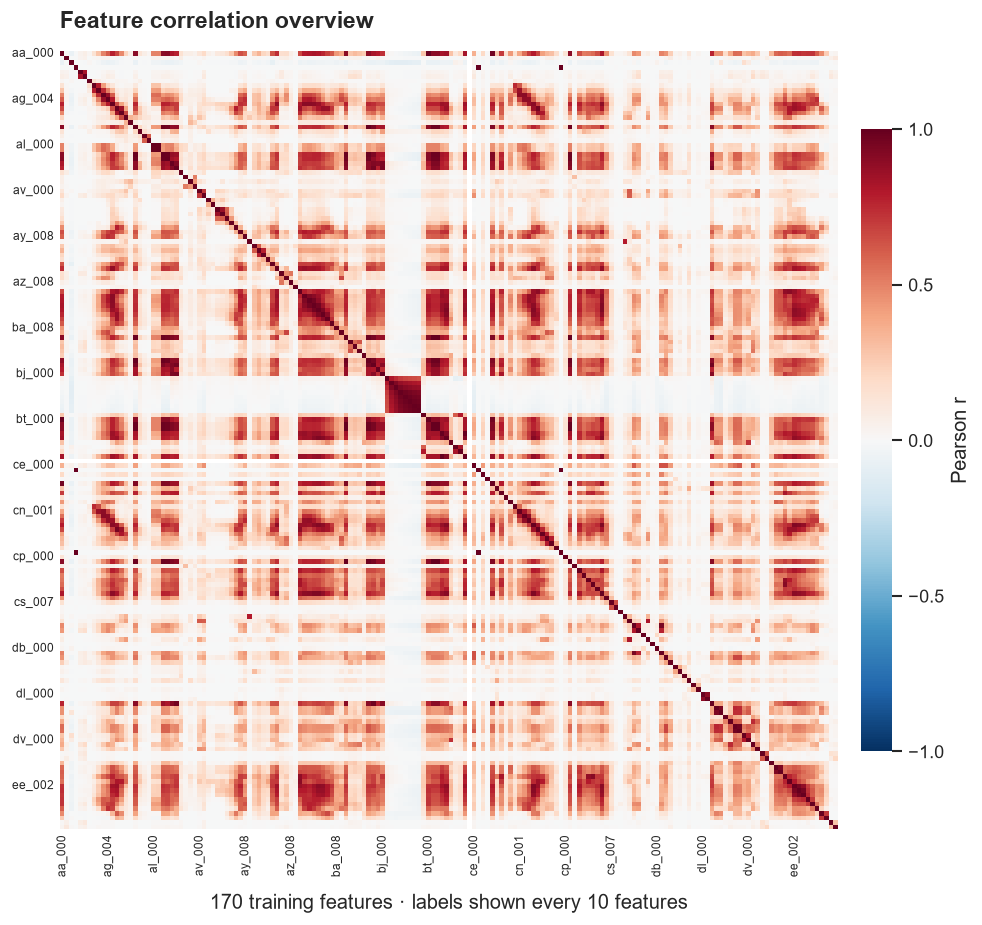

In [5]:
correlation_matrix = X_train.corr(method="pearson")

with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120, "font.size": 9}):
    fig, ax = plt.subplots(figsize=(9, 7.6), layout="constrained")
    sns.heatmap(
        correlation_matrix, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
        square=True, xticklabels=10, yticklabels=10, rasterized=True,
        cbar_kws={"label": "Pearson r", "shrink": 0.8, "pad": 0.025,
                  "ticks": [-1, -0.5, 0, 0.5, 1]},
    )
    ax.set_title("Feature correlation overview", loc="left", fontsize=14,
                 fontweight="bold", pad=14)
    ax.set_xlabel("170 training features · labels shown every 10 features", labelpad=10)
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0, labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=90, ha="center")
    plt.setp(ax.get_yticklabels(), rotation=0)
    plt.show()

### (b)(iv) Features with the highest CV

I selected $\lfloor\sqrt{170}\rfloor=13$ features for the scatterplots and boxplots.
I kept all 170 features for the models. I used `log(1 + value)` in the plots because
many features have large values and are strongly skewed.

In [6]:
top_features = feature_stats.head(math.isqrt(170)).index.tolist()
display(feature_stats.loc[top_features].round(6))
plot_data = np.log1p(X_train[top_features]).assign(label=train["class"])

,mean,sample_std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


For the scatterplot matrix, I sampled 3,000 negative and 1,000 positive observations
to reduce overlap and make both classes visible. The boxplots use all training rows.

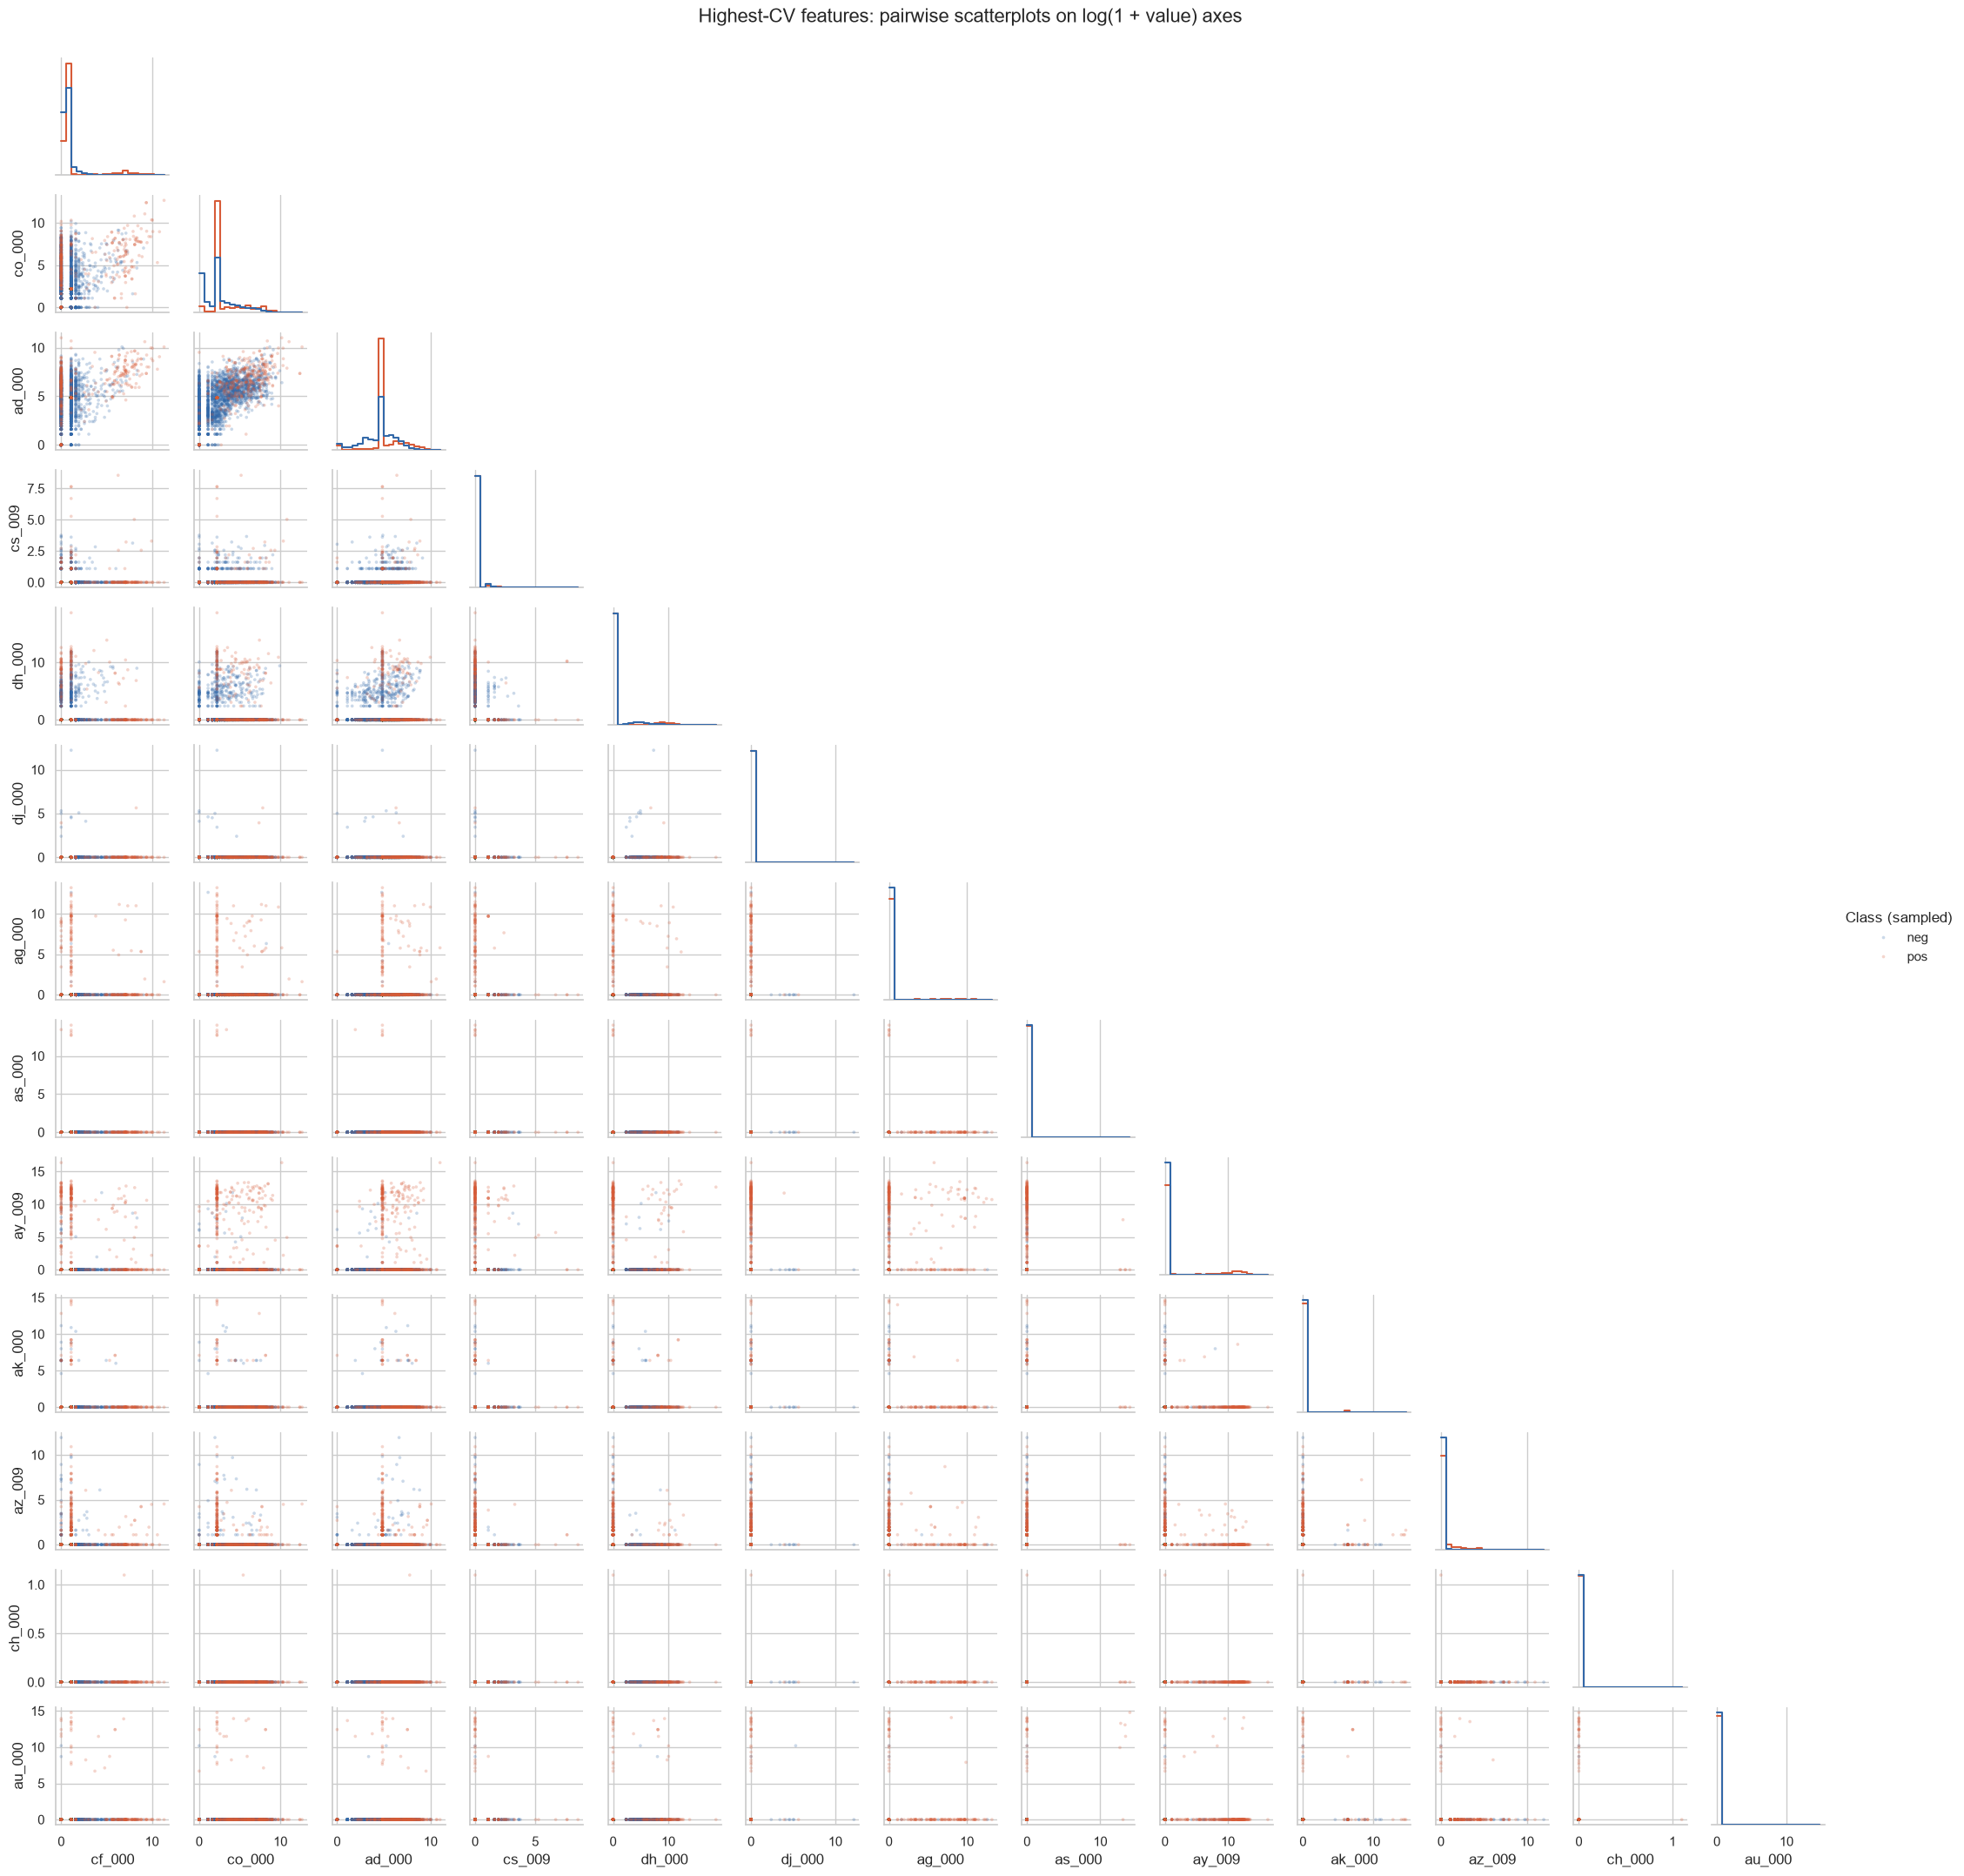

In [7]:
scatter_sample = pd.concat([
    plot_data.loc[plot_data["label"].eq(label)].sample(
        n=min(limit, int(plot_data["label"].eq(label).sum())), random_state=RANDOM_STATE
    )
    for label, limit in [("neg", 3000), ("pos", 1000)]
])

g = sns.PairGrid(scatter_sample, vars=top_features, hue="label",
                 hue_order=["neg", "pos"], palette=PALETTE,
                 corner=True, height=1.65, diag_sharey=False)
g.map_lower(sns.scatterplot, s=7, alpha=0.25, linewidth=0, rasterized=True)
g.map_diag(sns.histplot, bins=20, stat="density", element="step", fill=False,
           common_norm=False)
g.add_legend(title="Class (sampled)")
g.figure.suptitle("Highest-CV features: pairwise scatterplots on log(1 + value) axes",
                  y=1.01, fontsize=16)
plt.show()

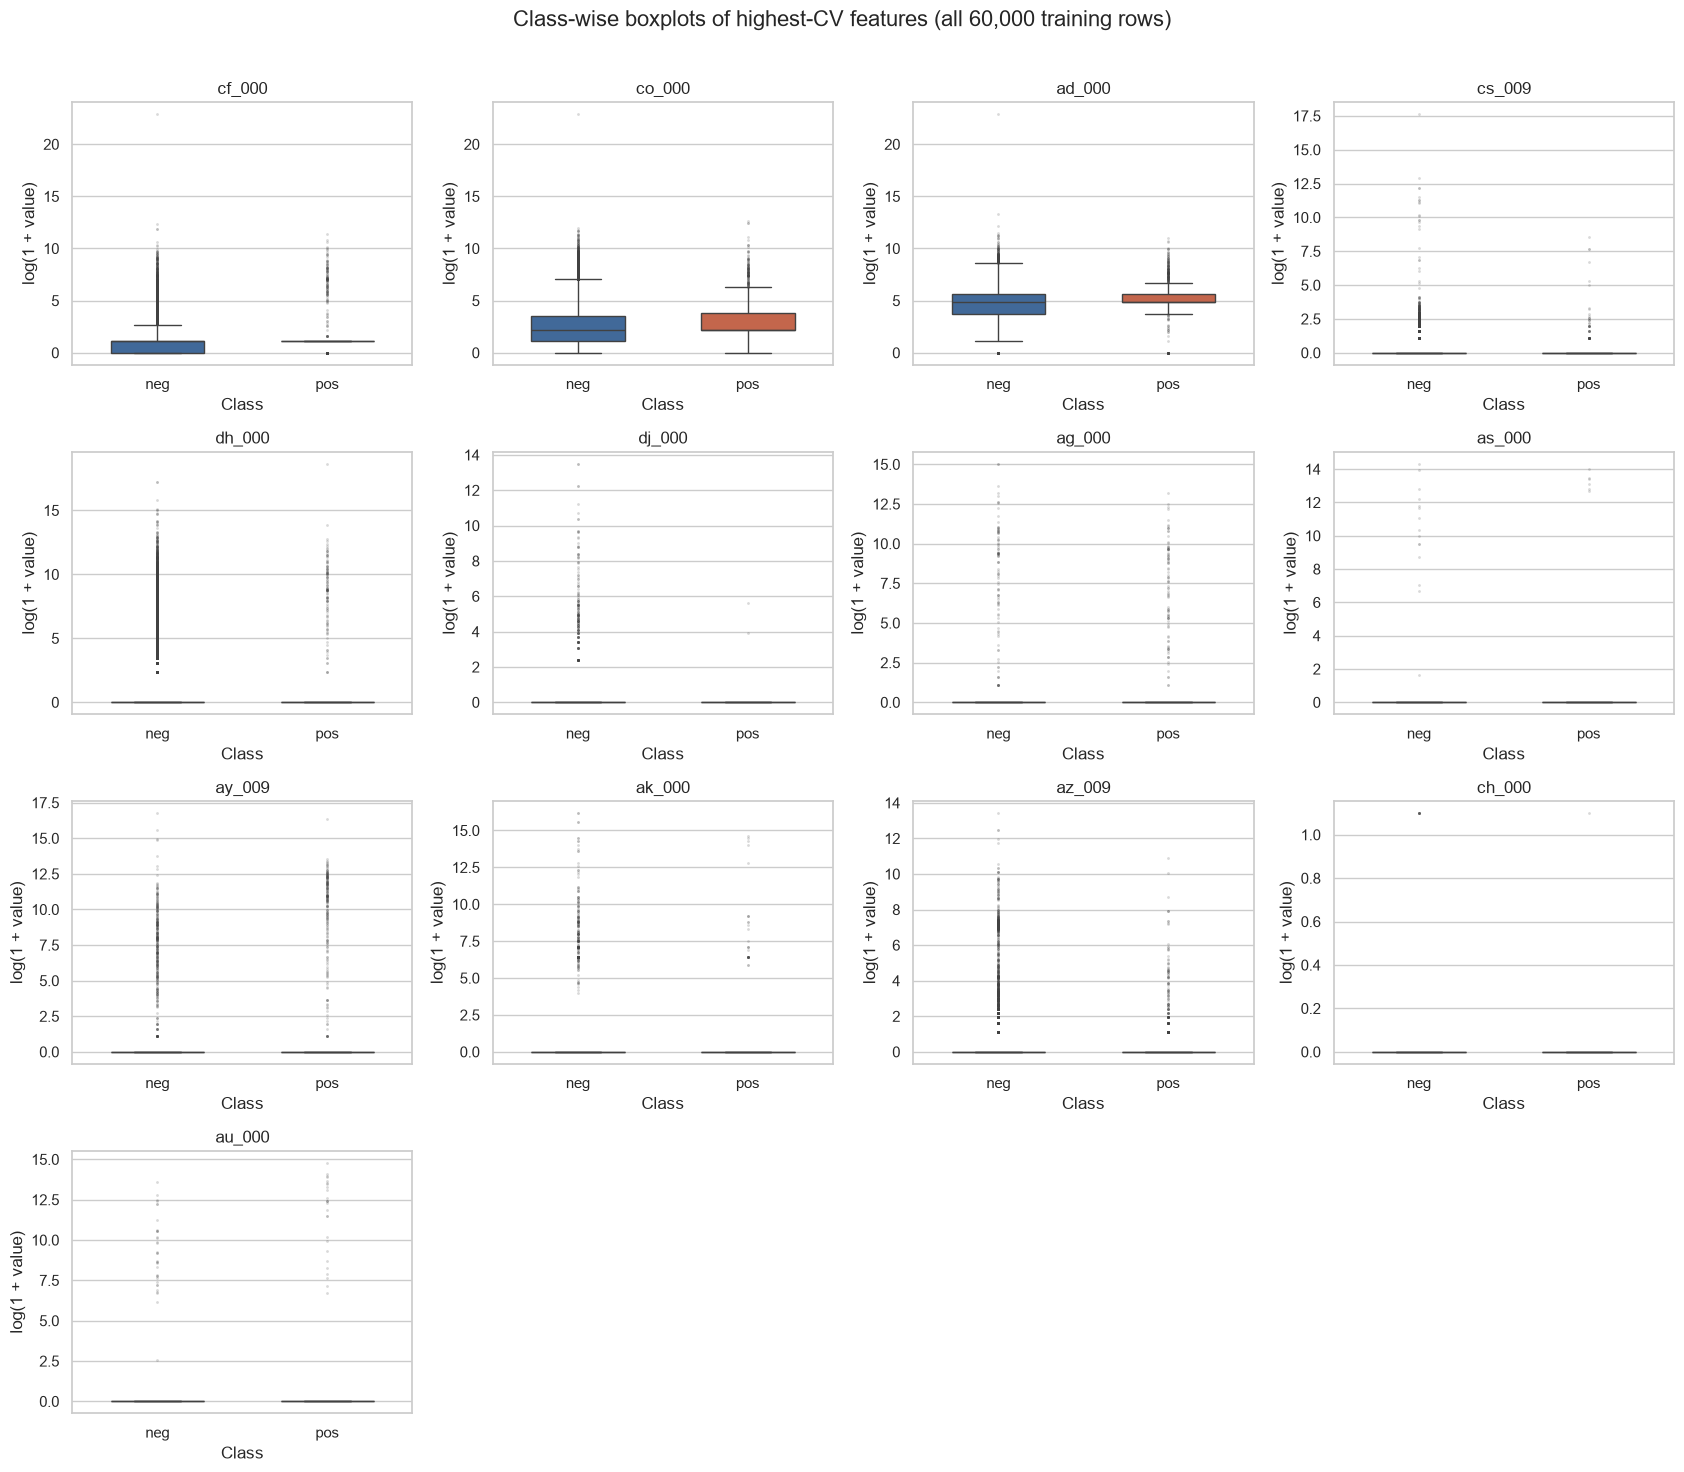

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(17, 15))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_data, x="label", y=feature, order=["neg", "pos"],
                hue="label", hue_order=["neg", "pos"], palette=PALETTE, legend=False,
                ax=ax, width=0.55,
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("log(1 + value)")
for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Class-wise boxplots of highest-CV features (all 60,000 training rows)",
             fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

The plots show many zero values, long tails, and overlap between the classes.
Some features have different distributions by class, but the scatterplots alone
do not establish their significance. A high CV measures relative variation, not
how useful a feature is for predicting the class.

### (b)(v) Class counts

In [9]:
class_counts = pd.DataFrame({"Training": train["class"].value_counts(),
                             "Test": test["class"].value_counts()}).reindex(["neg", "pos"])
display(class_counts)

,Training,Test
class,,
neg,59000,15625
pos,1000,375


The training set has **59,000 negatives and 1,000 positives**, giving a **59:1**
ratio. Only 1.67% of the training observations are positive, so the data are highly
imbalanced. The test set has 15,625 negatives and 375 positives.

### (c) Random forest without balancing

I fitted a random forest with 300 trees using all 170 features. I did not use class
weights or resampling. The misclassification rate is $(FP+FN)/N$. For ROC and AUC,
I used the predicted probability of the positive class.

In [10]:
rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", bootstrap=True,
                            oob_score=True, class_weight=None,
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

,Misclassified,Error (%),AUC
Split,,,
Training,0,0.00000,1.000000
Test,121,0.75625,0.994226


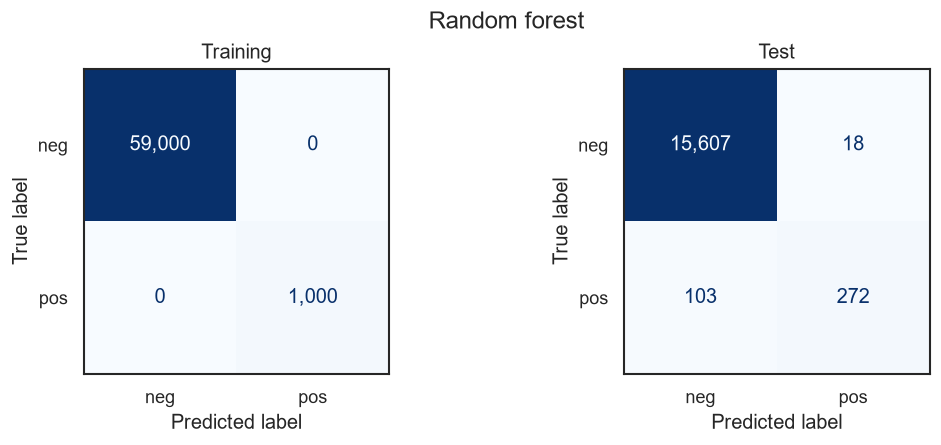

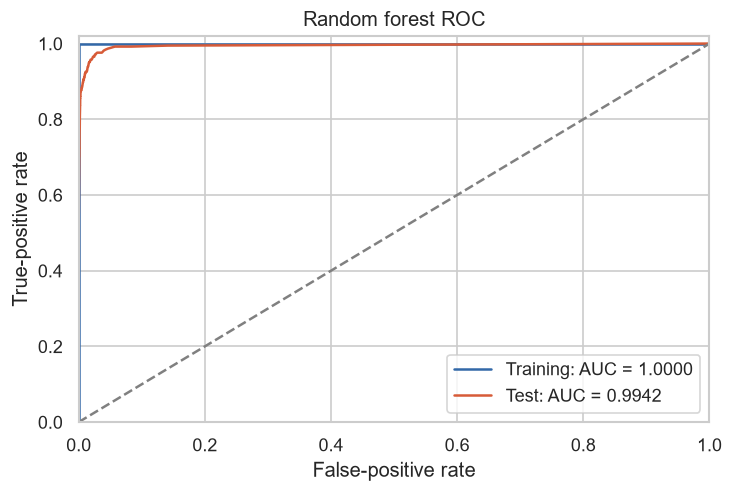

,Error (%)
OOB,0.573333
Test,0.756250


In [11]:
def evaluate_model(model, train_X, test_X, title):
    rows, matrices, curves = [], {}, {}
    for split, X, y in [("Training", train_X, y_train), ("Test", test_X, y_test)]:
        predicted = model.predict(X)
        probability = model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, predicted, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        matrices[split] = cm
        curves[split] = roc_curve(y, probability)
        rows.append({"Split": split, "Misclassified": fp + fn,
                     "Error (%)": 100 * (fp + fn) / len(y),
                     "AUC": roc_auc_score(y, probability)})
    results = pd.DataFrame(rows).set_index("Split")
    display(results.round(6))

    with sns.axes_style("white"), plt.rc_context({"figure.dpi": 120}):
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
        for ax, split in zip(axes, ["Training", "Test"]):
            ConfusionMatrixDisplay(matrices[split], display_labels=["neg", "pos"]).plot(
                ax=ax, cmap="Blues", colorbar=False, values_format=",d")
            ax.set_title(split)
            ax.grid(False)
        fig.suptitle(title)
        plt.show()

    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained", dpi=120)
    for split, color in [("Training", "#3268a8"), ("Test", "#d75b38")]:
        fpr, tpr, _ = curves[split]
        ax.plot(fpr, tpr, color=color, label=f"{split}: AUC = {results.loc[split, 'AUC']:.4f}")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="False-positive rate", ylabel="True-positive rate",
           title=title + " ROC", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend()
    plt.show()
    return results, matrices

rf_results, rf_matrices = evaluate_model(rf, X_train, X_test, "Random forest")
rf_oob_error = 100 * (1 - rf.oob_score_)
display(pd.DataFrame({"Error (%)": [rf_oob_error, rf_results.loc["Test", "Error (%)"]]},
                     index=["OOB", "Test"]).round(6))

The training error is 0%, while the test error is 0.75625%. The OOB error is about
0.5733%, which is lower than the test error by about 0.1829 percentage points.
The test confusion matrix has 18 false positives and 103 false negatives.

### (d) Random forest with class balancing

Random forests can handle imbalance by giving the minority class a larger weight
or by balancing the samples used to train the trees. Oversampling methods such as
SMOTE are another option.

I used `class_weight="balanced_subsample"`, which calculates inverse-frequency
class weights separately for each bootstrap sample. This gives the classes equal
total weight within each tree. Based on the full training counts, a positive
observation would have 59 times the weight of a negative one. I kept the other
forest settings the same as in (c).

Sources: [random forest class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
and [balanced random forests](https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedRandomForestClassifier.html).

,Misclassified,Error (%),AUC
Split,,,
Training,0,0.0000,1.000000
Test,178,1.1125,0.993133


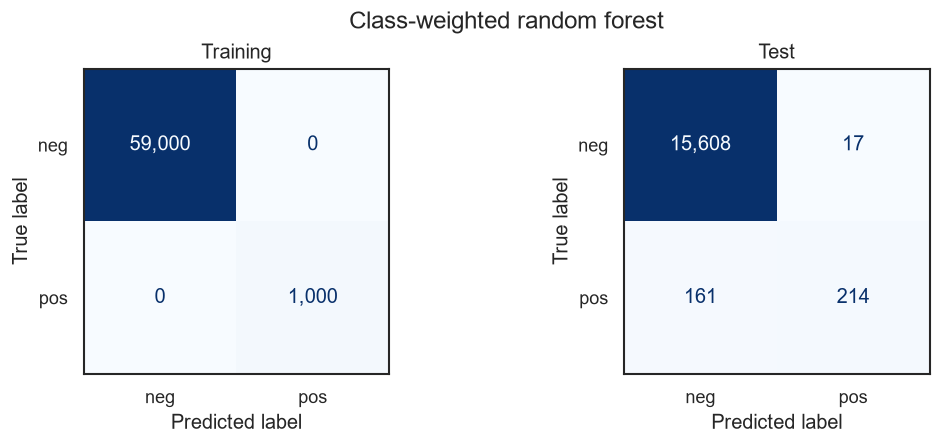

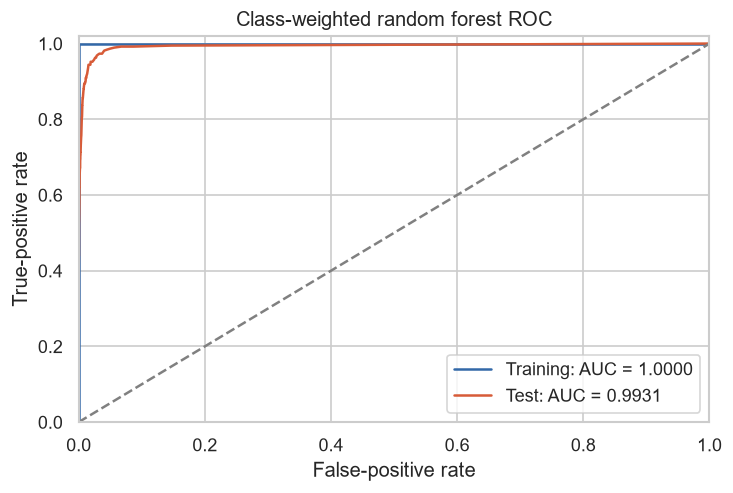

,OOB error (%),Test error (%)
Unweighted,0.573333,0.75625
Class-weighted,0.756667,1.11250


In [12]:
from sklearn.base import clone

weighted_rf = clone(rf).set_params(class_weight="balanced_subsample")
weighted_rf.fit(X_train, y_train)
weighted_results, weighted_matrices = evaluate_model(weighted_rf, X_train, X_test,
                                                    "Class-weighted random forest")
weighted_oob_error = 100 * (1 - weighted_rf.oob_score_)
display(pd.DataFrame({"OOB error (%)": [rf_oob_error, weighted_oob_error],
                      "Test error (%)": [rf_results.loc["Test", "Error (%)"],
                                         weighted_results.loc["Test", "Error (%)"]]},
                     index=["Unweighted", "Class-weighted"]).round(6))

Weighting did not improve the result here. The test error increased from 0.75625%
to 1.1125%, and AUC decreased from about 0.9942 to 0.9931. False negatives increased
from 103 to 161, while false positives decreased from 18 to 17. The weighted
forest's OOB error is about 0.7567%, compared with its test error of 1.1125%.

### (e) XGBoost with L1 regularization

Following the professor's clarification, I used standard XGBoost with L1
regularization. I tuned `reg_alpha` over 0.01, 0.1, 1, and 10 using stratified
five-fold cross-validation, choosing the value with the lowest misclassification
rate. I used 150 trees, depth 3, and a learning rate of 0.1, without class balancing.

I put median imputation, a log transformation, and scaling inside the pipeline,
so they are fitted separately within each training fold. I used the same
preprocessing in (f), where scaling is useful for SMOTE's distance calculations.

Source: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).

,alpha,CV error (%)
0,0.01,0.638333
1,0.10,0.643333
2,1.00,0.655000
3,10.00,0.741667


Selected alpha: 0.01


,Misclassified,Error (%),AUC
Split,,,
Training,217,0.361667,0.998050
Test,132,0.825000,0.995631


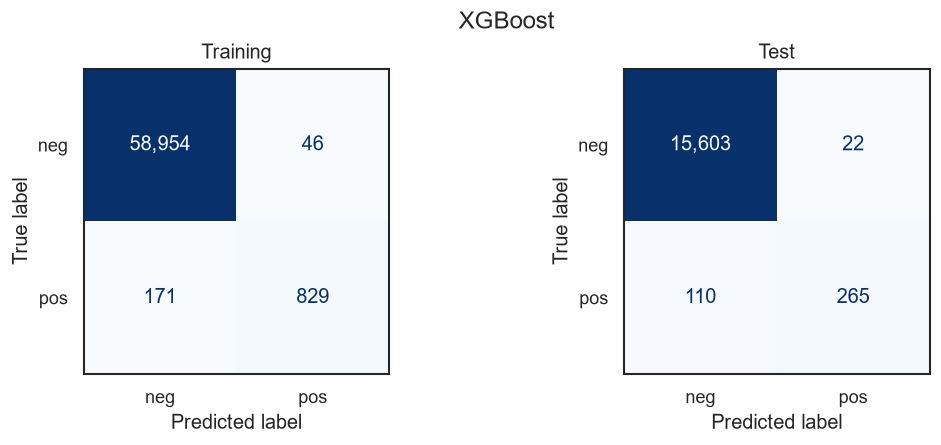

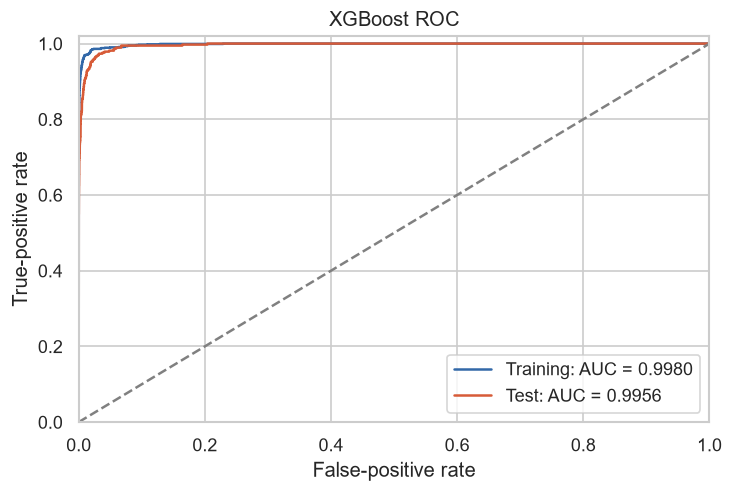

,Error (%)
Five-fold CV,0.638333
Test,0.825000


In [13]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alpha_grid = {"model__reg_alpha": [0.01, 0.1, 1.0, 10.0]}

def make_xgb_pipeline(use_smote=False):
    steps = [("imputer", SimpleImputer(strategy="median")),
             ("log", FunctionTransformer(np.log1p)),
             ("scaler", StandardScaler())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", XGBClassifier(
        booster="gbtree", objective="binary:logistic", eval_metric="logloss",
        n_estimators=150, max_depth=3, learning_rate=0.1, reg_lambda=0,
        scale_pos_weight=1, tree_method="hist", random_state=RANDOM_STATE, n_jobs=2)))
    return Pipeline(steps)

def tune_xgb(use_smote=False):
    search = GridSearchCV(make_xgb_pipeline(use_smote), alpha_grid, scoring="accuracy",
                          cv=cv, n_jobs=2, pre_dispatch=2)
    search.fit(X_train_raw, y_train)
    display(pd.DataFrame({
        "alpha": search.cv_results_["param_model__reg_alpha"],
        "CV error (%)": 100 * (1 - search.cv_results_["mean_test_score"]),
    }).round(6))
    print("Selected alpha:", search.best_params_["model__reg_alpha"])
    return search

xgb_plain = tune_xgb()
xgb_plain_results, xgb_plain_matrices = evaluate_model(
    xgb_plain.best_estimator_, X_train_raw, X_test_raw, "XGBoost")
display(pd.DataFrame({"Error (%)": [100 * (1 - xgb_plain.best_score_),
                                    xgb_plain_results.loc["Test", "Error (%)"]]},
                     index=["Five-fold CV", "Test"]).round(6))

The selected alpha is 0.01. Its five-fold CV error is about 0.6383%, compared with
a test error of 0.8250%. The training error is about 0.3617%. The training and test
AUCs are about 0.9981 and 0.9956. I used CV to choose alpha and the separate test
set to evaluate the final model.

### (f) SMOTE followed by XGBoost

I repeated (e) with SMOTE to balance the fitting data. SMOTE is inside the
pipeline, after imputation and scaling. During cross-validation it is applied
only to the training fold. The validation fold and test set are not resampled.
Applying SMOTE before splitting into folds would leak information between them.

Source: [imbalanced-learn: avoiding resampling leakage](https://imbalanced-learn.org/stable/common_pitfalls.html).

,alpha,CV error (%)
0,0.01,1.710000
1,0.10,1.715000
2,1.00,1.695000
3,10.00,1.746667


Selected alpha: 1.0


,Misclassified,Error (%),AUC
Split,,,
Training,853,1.421667,0.996279
Test,259,1.618750,0.993958


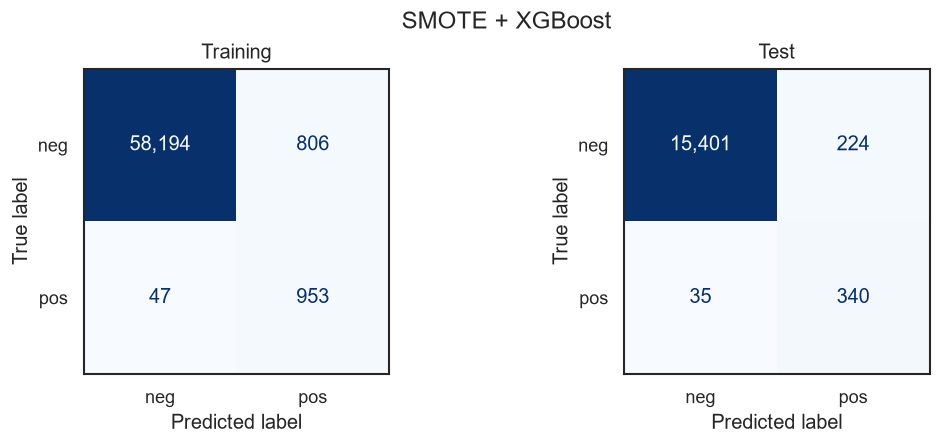

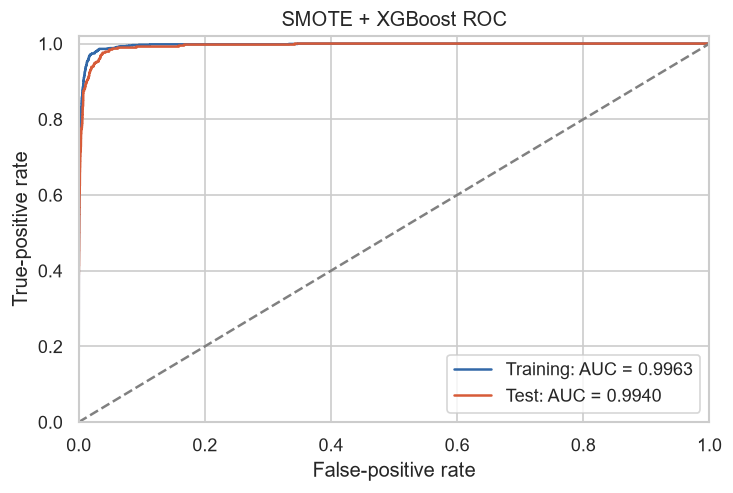

,CV error (%),Test error (%)
Without SMOTE,0.638333,0.82500
With SMOTE,1.695000,1.61875


Misclassified  Error (%)       AUC
Model         Split                                       
Without SMOTE Training            217   0.361667  0.998050
              Test                132   0.825000  0.995631
With SMOTE    Training            853   1.421667  0.996279
              Test                259   1.618750  0.993958

In [14]:
xgb_smote = tune_xgb(use_smote=True)
xgb_smote_results, xgb_smote_matrices = evaluate_model(
    xgb_smote.best_estimator_, X_train_raw, X_test_raw, "SMOTE + XGBoost")
display(pd.DataFrame({"CV error (%)": [100 * (1 - xgb_plain.best_score_),
                                      100 * (1 - xgb_smote.best_score_)],
                      "Test error (%)": [xgb_plain_results.loc["Test", "Error (%)"],
                                         xgb_smote_results.loc["Test", "Error (%)"]]},
                     index=["Without SMOTE", "With SMOTE"]).round(6))
display(pd.concat({"Without SMOTE": xgb_plain_results,
                   "With SMOTE": xgb_smote_results}, names=["Model", "Split"]).round(6))

With SMOTE, the selected alpha is 1 and the CV error is 1.6950%. The test error
increased from 0.8250% to 1.61875%, and test AUC decreased from about 0.9956 to
0.9940. However, false negatives decreased from 110 to 35, while false positives
increased from 22 to 224. SMOTE helped detect more APS failures, but it also led
to more unnecessary positive predictions.

## 2. Lasso and the Bias–Variance Trade-off

This is lasso regression with the constraint $\sum_{j=1}^{p}|\beta_j|\leq s$.
At $s=0$, all slopes are zero. Increasing $s$ relaxes the constraint and makes
the model more flexible.

### (a) Training RSS: iv. Steadily decrease

Increasing $s$ gives more possible coefficient values, so the minimum training RSS
cannot increase. It decreases or stays unchanged, becoming constant once the
least-squares solution is allowed.

### (b) Test RSS: ii. Decrease initially, then increase in a U shape

At first, increasing $s$ reduces underfitting and lowers test RSS. With a large
$s$, the model can fit more noise, so test RSS tends to rise. This gives the usual
U-shaped pattern.

### (c) Variance: iii. Steadily increase

A less constrained model is more sensitive to the training sample, so its variance
generally increases.

### (d) Squared bias: iv. Steadily decrease

Relaxing the constraint lets the model capture more of the underlying relationship,
so squared bias generally decreases.

### (e) Irreducible error: v. Remain constant

The noise in the data does not depend on $s$. Therefore, the irreducible error
stays the same.

## 3. Ridge and Lasso with Identical Predictors

The predictors and response are centered, so $\hat\beta_0=0$. Let
$a=x_{11}=x_{12}$ and $b=y_1$. Then $x_{21}=x_{22}=-a$ and $y_2=-b$.
I take $\lambda>0$ below.

### (a) Ridge optimization problem

$$
\min_{\beta_1,\beta_2}
\left\{(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda(\beta_1^2+\beta_2^2)\right\}.
$$

Using the given equalities, this becomes

$$
\min_{\beta_1,\beta_2}
\left\{2[b-a(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2)\right\}.
$$

### (b) Why the ridge coefficients are equal

Setting the two partial derivatives to zero gives

$$
-4a[b-a(\beta_1+\beta_2)]+2\lambda\beta_1=0,
$$
$$
-4a[b-a(\beta_1+\beta_2)]+2\lambda\beta_2=0.
$$

Subtracting gives $2\lambda(\beta_1-\beta_2)=0$. Since $\lambda>0$,

$$\boxed{\hat\beta_1=\hat\beta_2.}$$

### (c) Lasso optimization problem

$$
\min_{\beta_1,\beta_2}
\left\{(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda(|\beta_1|+|\beta_2|)\right\}.
$$

Equivalently,

$$
\min_{\beta_1,\beta_2}
\left\{2[b-a(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|)\right\}.
$$

### (d) Lasso solutions

The RSS depends only on $z=\beta_1+\beta_2$. For any fixed $z$,
$|\beta_1|+|\beta_2|\geq|z|$, with equality when both coefficients have the same
sign, including zero. The problem therefore reduces to minimizing
$2(b-az)^2+\lambda|z|$ over $z$.

If the optimal sum is $\hat z\ne0$, every pair

$$
\boxed{(\hat\beta_1,\hat\beta_2)=(t\hat z,(1-t)\hat z),\quad 0\leq t\leq1}
$$

has the same RSS and penalty. These solutions form the line segment from
$(\hat z,0)$ to $(0,\hat z)$. For example, lasso can put all the coefficient on
either predictor or split it equally. This explains the non-uniqueness.
If the penalty shrinks the optimal sum to zero, the solution is instead uniquely
$(0,0)$ for $\lambda>0$.

## 4. Majority Vote vs. Average Probability

### Majority vote

Six estimates are above 0.5: $0.55,0.60,0.60,0.65,0.70,0.75$.
These trees vote Red. The other four vote Green, so the final prediction is **Red**.

### Average probability

$$
\bar p_{\text{Red}}=
\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}
=\frac{4.50}{10}=0.45.
$$

Since $0.45<0.5$, the final prediction is **Green**. Majority voting counts the
individual class predictions, while averaging also accounts for the sizes of
the probability estimates.

## 5. Maximal Margin Classifier

The four panels below show the observations, the optimal separator and margins,
a nonoptimal separator, and an added Blue observation.

,X1,X2,Class
Observation,,,
1,3,4,Red
2,2,2,Red
3,4,4,Red
4,1,4,Red
5,2,1,Blue
6,4,3,Blue
7,4,1,Blue


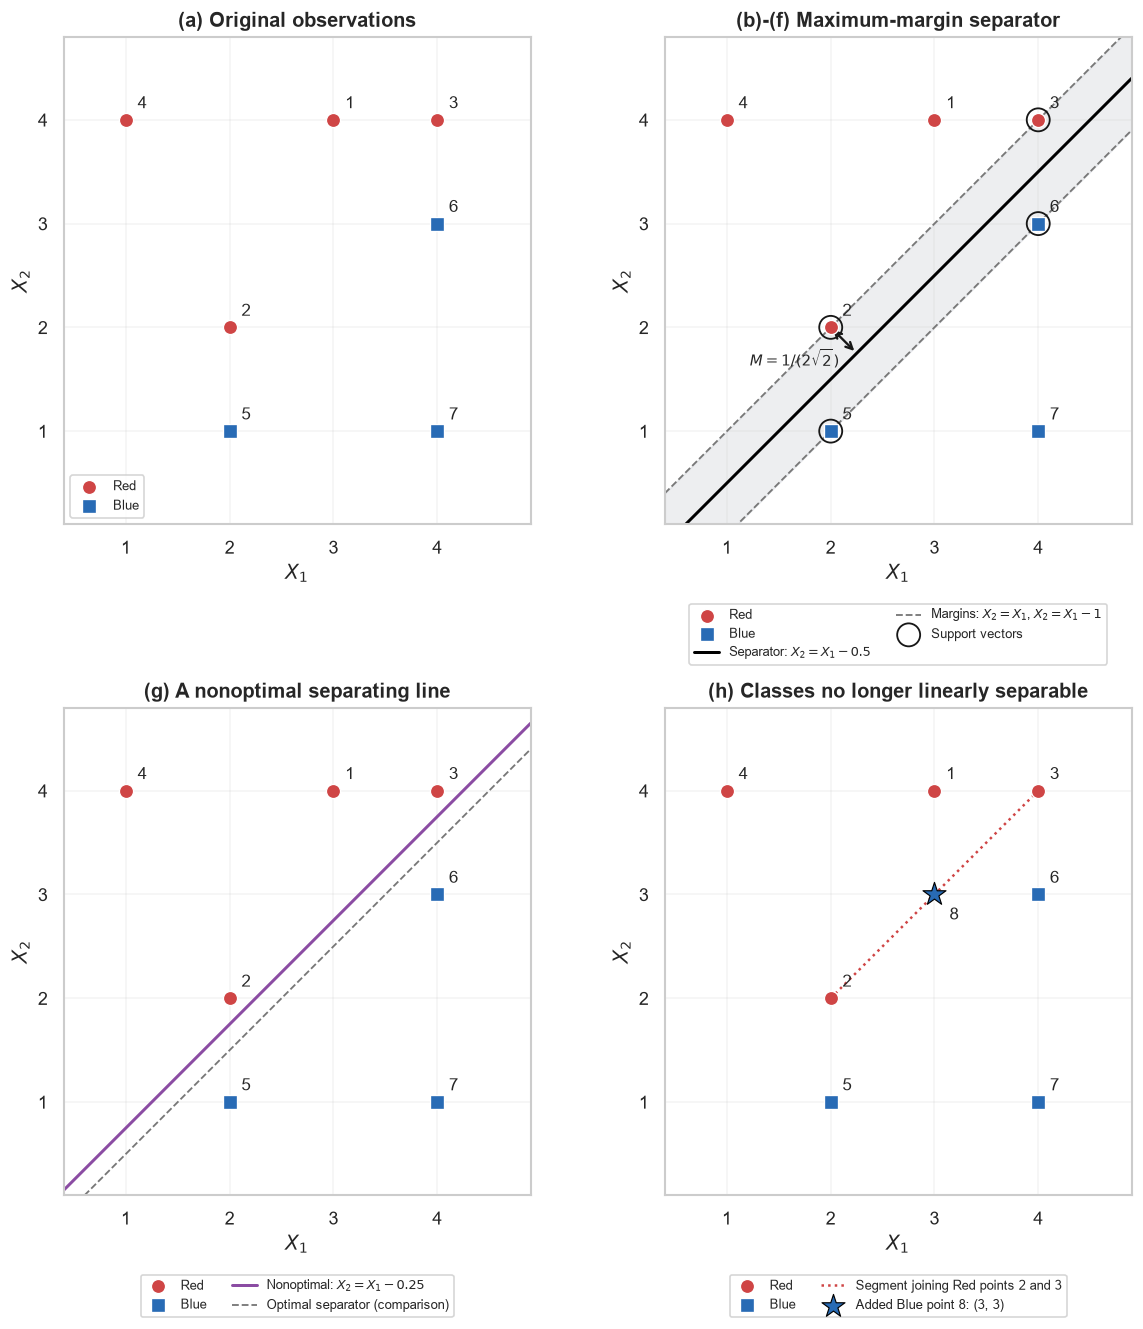

Margin on each side: 0.353553
Total width between margin lines: 0.707107
Support-vector observations: [2, 3, 5, 6]


In [15]:
toy = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Class": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"],
}, index=pd.Index(range(1, 8), name="Observation"))
display(toy)

toy_score = 0.5 - toy["X1"] + toy["X2"]
toy_y = np.where(toy["Class"].eq("Red"), 1, -1)
toy_distances = toy_y * toy_score.to_numpy() / np.sqrt(2)
toy_margin = toy_distances.min()
toy_support = toy.index[np.isclose(toy_distances, toy_margin)].tolist()

def draw_toy(ax):
    for label, color, marker in [("Red", "#cf4545", "o"), ("Blue", "#286bb5", "s")]:
        points = toy.loc[toy["Class"].eq(label)]
        ax.scatter(points["X1"], points["X2"], color=color, marker=marker,
                   s=72, edgecolor="white", linewidth=0.8, label=label, zorder=4)
    for obs, row in toy.iterrows():
        ax.annotate(str(obs), (row["X1"], row["X2"]), xytext=(7, 7),
                    textcoords="offset points", fontsize=10, zorder=6)
    ax.set(xlim=(0.4, 4.9), ylim=(0.1, 4.8), xlabel=r"$X_1$", ylabel=r"$X_2$")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_yticks([1, 2, 3, 4])
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

with plt.rc_context({"figure.dpi": 120, "font.size": 10}):
    fig, axes = plt.subplots(2, 2, figsize=(10, 11), layout="constrained")
    xx = np.linspace(0.4, 4.9, 300)
    for ax in axes.flat:
        draw_toy(ax)

    axes[0, 0].set_title("(a) Original observations", fontweight="bold")
    axes[0, 0].legend(loc="lower left", fontsize=8)

    ax = axes[0, 1]
    ax.fill_between(xx, xx - 1, xx, color="#b9bdc7", alpha=0.25, zorder=0)
    ax.plot(xx, xx - 0.5, color="black", linewidth=1.8,
            label=r"Separator: $X_2=X_1-0.5$")
    ax.plot(xx, xx, "--", color="#777777", linewidth=1.1,
            label=r"Margins: $X_2=X_1$, $X_2=X_1-1$")
    ax.plot(xx, xx - 1, "--", color="#777777", linewidth=1.1)
    sv = toy.loc[toy_support]
    ax.scatter(sv["X1"], sv["X2"], s=190, facecolors="none",
               edgecolors="#171717", linewidth=1.1, zorder=5, label="Support vectors")
    # The arrow is perpendicular to the separator and spans one margin.
    ax.annotate("", xy=(2, 2), xytext=(2.25, 1.75),
                arrowprops={"arrowstyle": "<->", "color": "#171717", "lw": 1.4})
    ax.text(1.22, 1.63, r"$M=1/(2\sqrt{2})$", fontsize=9)
    ax.set_title("(b)-(f) Maximum-margin separator", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)

    ax = axes[1, 0]
    ax.plot(xx, xx - 0.25, color="#8b4ca3", linewidth=1.8,
            label=r"Nonoptimal: $X_2=X_1-0.25$")
    ax.plot(xx, xx - 0.5, "--", color="#777777", linewidth=1.1,
            label="Optimal separator (comparison)")
    ax.set_title("(g) A nonoptimal separating line", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)

    ax = axes[1, 1]
    ax.plot([2, 4], [2, 4], ":", color="#cf4545", linewidth=1.5,
            label="Segment joining Red points 2 and 3", zorder=2)
    ax.scatter([3], [3], color="#286bb5", marker="*", s=210,
               edgecolor="black", linewidth=0.7, zorder=6, label="Added Blue point 8: (3, 3)")
    ax.annotate("8", (3, 3), xytext=(9, -15), textcoords="offset points", fontsize=10)
    ax.set_title("(h) Classes no longer linearly separable", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=7.5)
    plt.show()

print(f"Margin on each side: {toy_margin:.6f}")
print(f"Total width between margin lines: {2 * toy_margin:.6f}")
print("Support-vector observations:", toy_support)

### (a) Sketch

The upper-left panel shows the seven observations, labeled by their observation
numbers. Observations 1–4 are Red and 5–7 are Blue.

### (b) Optimal separating hyperplane

The closest Red points lie on $X_2=X_1$, and the closest Blue points lie on
$X_2=X_1-1$. The line halfway between these boundaries is

$$\boxed{X_2=X_1-\tfrac12},\qquad\text{or}\qquad\tfrac12-X_1+X_2=0.$$

This gives the largest minimum distance to the two classes.

### (c) Classification rule

I use $\beta_0=\tfrac12$, $\beta_1=-1$, and $\beta_2=1$.
Classify as **Red** if $\tfrac12-X_1+X_2>0$, and **Blue** otherwise.

### (d) Margin

The dashed margin lines are $X_2=X_1$ and $X_2=X_1-1$. Using a closest point,
such as $(2,2)$, the perpendicular distance to the separator is

$$\boxed{M=\frac{|\tfrac12-2+2|}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt2}\approx0.3536.}$$

This is the margin on each side. The total width is $2M\approx0.7071$.

### (e) Support vectors

The support vectors are Red observations **2 and 3**, at $(2,2)$ and $(4,4)$,
and Blue observations **5 and 6**, at $(2,1)$ and $(4,3)$. They lie on the
margin lines and are circled in the plot.

### (f) Moving observation 7

Observation 7 at $(4,1)$ is not a support vector and is far from the margin.
A slight movement that leaves it outside the Blue margin does not change the
support vectors or the maximal-margin separator.

### (g) A nonoptimal separating hyperplane

One example is $\boxed{X_2=X_1-\tfrac14}$. It still separates the classes, but
its minimum distance to a Red point is only $1/(4\sqrt2)\approx0.1768$.
This is smaller than the optimal margin.

### (h) Add an observation so the classes are not separable

I add a **Blue point at $(3,3)$**, shown as a star. It is the midpoint of Red
points $(2,2)$ and $(4,4)$. Any half-plane containing both Red endpoints also
contains their midpoint, so no line can strictly separate this Blue point from
both Red points.